In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"..\datasets\clean_dataset.csv")
df.head(5)

,appointment_id,patient_id,age,gender,postcode_area,distance_to_clinic_km,clinic_id,clinic_type,appointment_type,consultation_fee,...,days_since_last_visit,has_chronic_condition_flag,sms_reminder_sent,reminder_hours_before,reminder_response,number_of_reminders_sent,estimated_revenue_loss_gbp,staff_idle_cost_gbp,slot_rebooked_flag,no_show
0,1,861,53,Male,B15,6.2,C1,Physiotherapy,New Patient,93,...,204,0,1,48,Confirmed,1,0,0.00,0,0
1,2,1295,32,Male,CF10,5.9,C3,GP,Follow-up,68,...,123,1,1,24,Confirmed,1,68,23.80,1,1
2,3,1131,18,Male,BS1,3.6,C2,Physiotherapy,Follow-up,104,...,9,0,1,24,Confirmed,1,0,0.00,0,0
3,4,1096,43,Female,M1,7.5,C4,GP,Follow-up,93,...,55,0,1,48,Confirmed,1,93,32.55,0,1
4,5,1639,21,Male,G1,5.5,C5,Dermatology,New Patient,182,...,105,0,0,24,No Reminder,1,182,63.70,1,1


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
appointment_id,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.00
patient_id,10000.0,1502.626900,865.021722,1.0,762.75,1493.0,2250.25,3000.00
age,10000.0,41.867300,14.178180,18.0,32.00,41.0,51.00,90.00
distance_to_clinic_km,10000.0,6.020870,4.283646,0.5,2.90,5.0,8.20,35.00
consultation_fee,10000.0,103.188400,33.563077,60.0,78.00,92.0,125.00,199.00
appointment_hour,10000.0,12.960800,2.597140,9.0,11.00,13.0,15.00,17.00
day_gap,10000.0,13.530600,8.085258,0.0,7.00,14.0,21.00,27.00
is_weekend,10000.0,0.278800,0.448431,0.0,0.00,0.0,1.00,1.00
is_peak_hour,10000.0,0.326800,0.469067,0.0,0.00,0.0,1.00,1.00
patient_total_appointments,10000.0,1.961400,1.370145,1.0,1.00,1.0,3.00,11.00


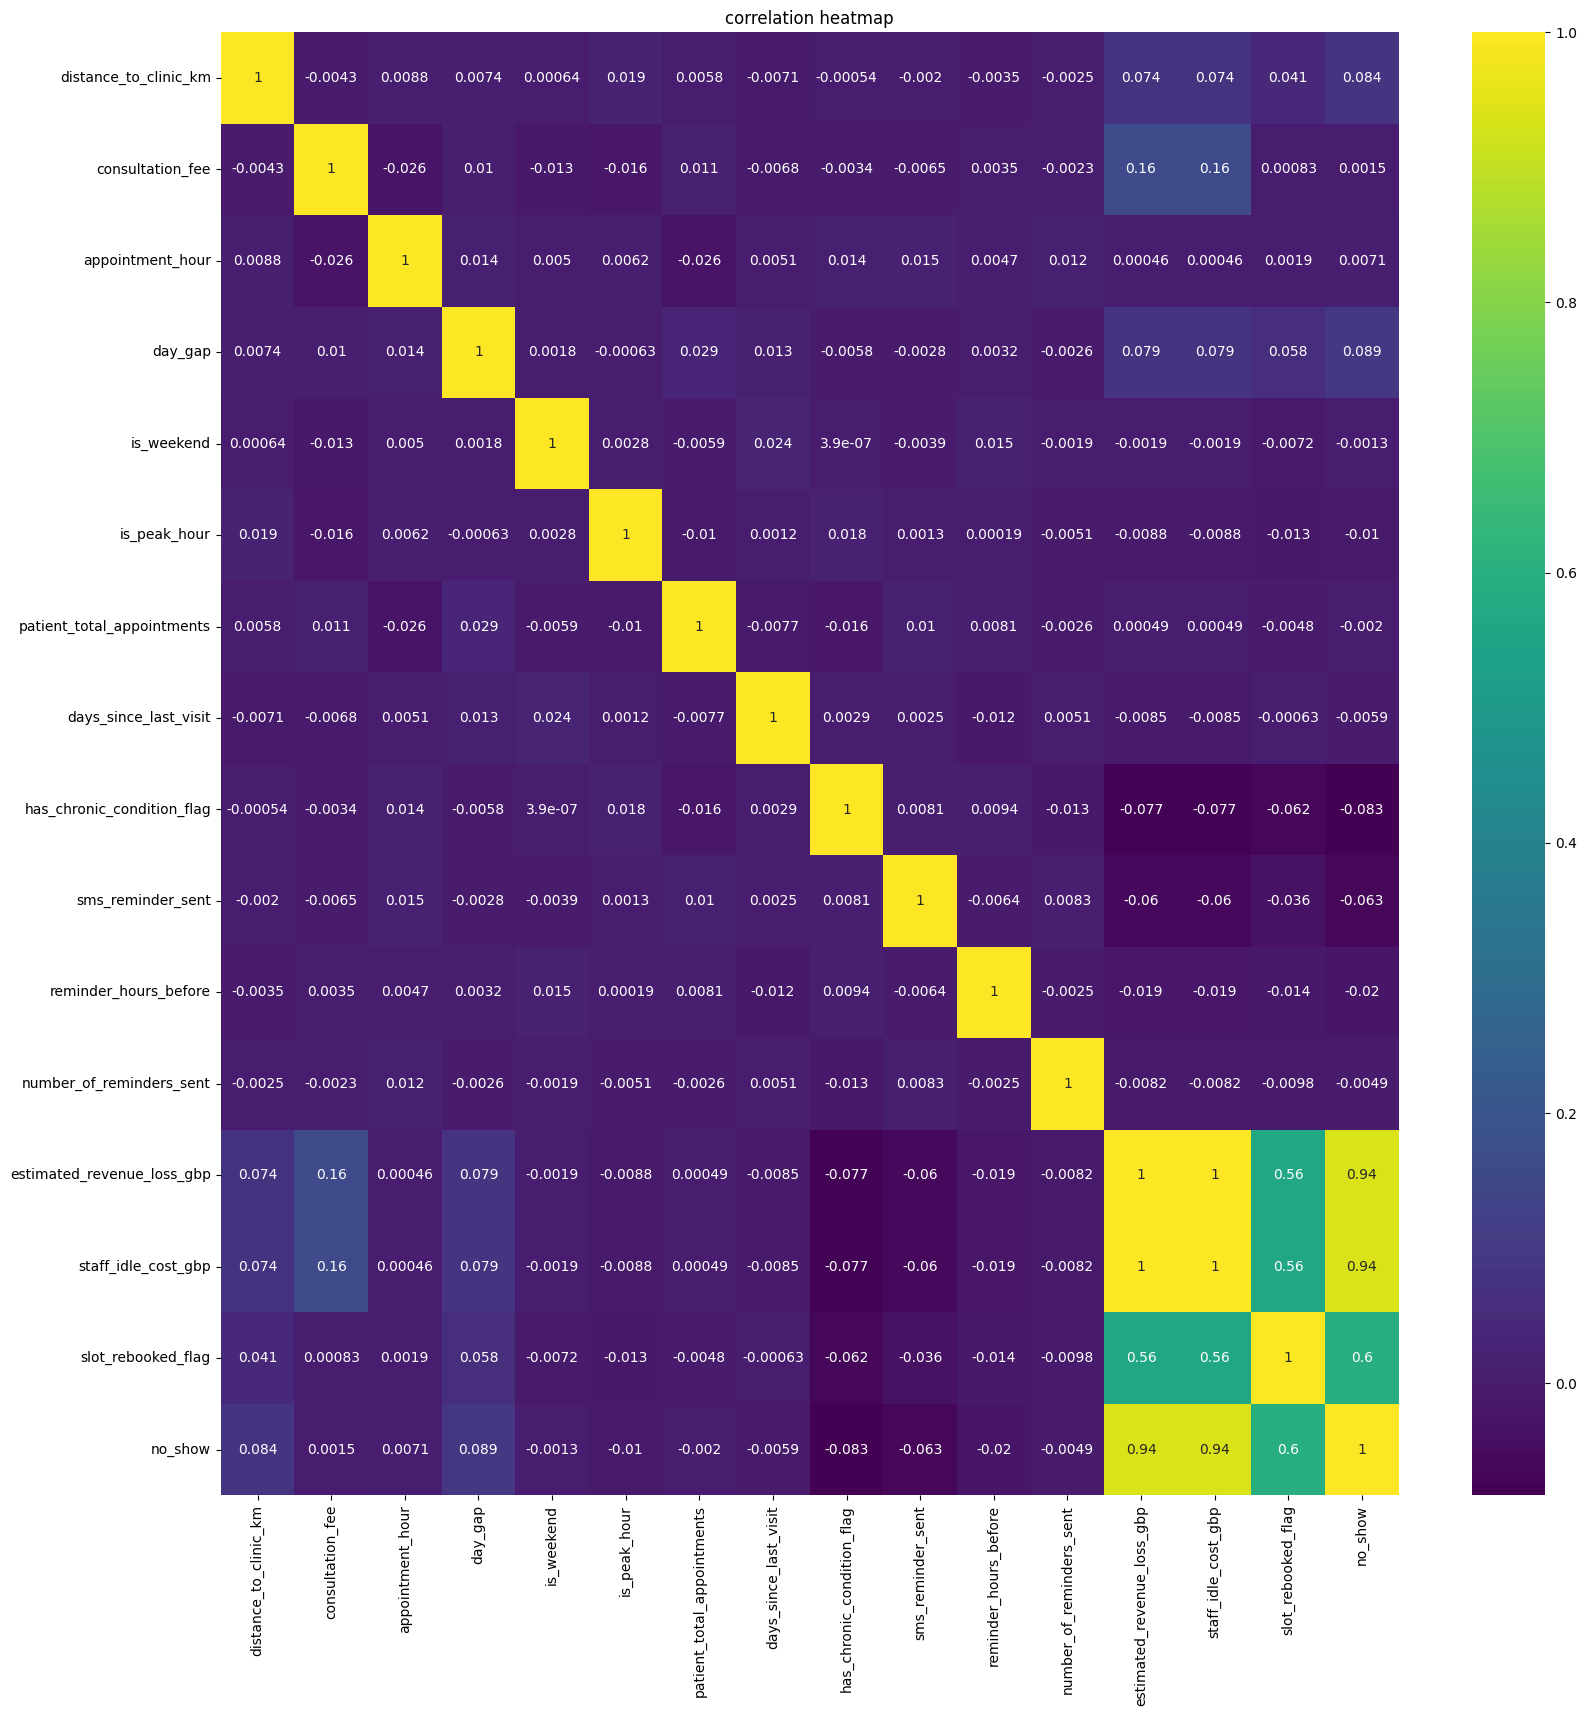

In [9]:
drop_col = df.drop(columns=['appointment_id' , 'patient_id' , 'age' , 'missed_appointment','patient_noshow_rate'])
numeric_cols = drop_col.select_dtypes(include=['int64','float32','int32','float64'])
plt.figure(figsize=(19,19))
sns.heatmap(numeric_cols.corr() , annot=True ,cmap="viridis" )
plt.title("correlation heatmap")
plt.show()

1 . **Strong Leakage Features**

-> estimated_revenue_loss_gbp and staff_idle_cost_gbp show almost perfect correlation with no_show (0.94) and with each other (1.00).

2 . **Moderate Link with Slot Rebooking**

-> slot_rebooked_flag has a correlation of 0.60 with no_show. This makes sense — when a patient does not show up, the clinic tries to rebook the slot. However, this feature is also partly outcome-dependent and should be used carefully.

4 . **Very Weak relationship**

-> Most features (distance, appointment hour, weekend flag, peak hour, total appointments, reminder-related columns) have correlations close to zero with no_show

5 . **Slight Positive Signals**

-> day_gap (days in advance) → +0.089
distance_to_clinic_km → +0.084

* show outliers

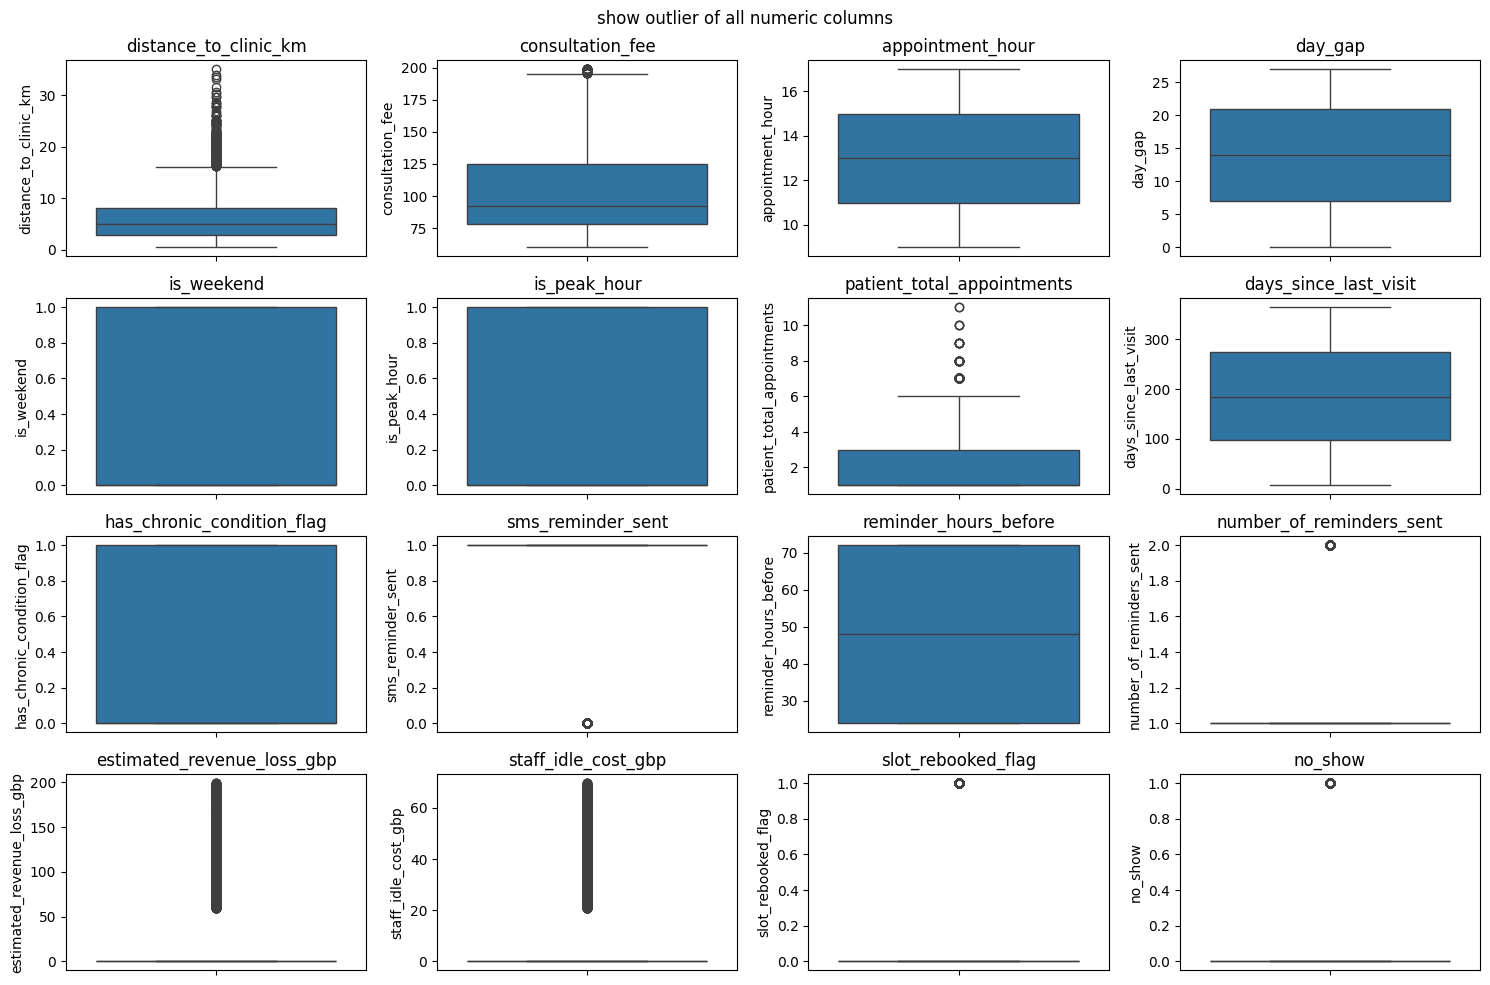

In [10]:
# numerical_cols = df.select_dtypes(include=["float64", "int64"]).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(4, 4, i + 1) # adjust the number of rows and columns as needed
    sns.boxplot(df[col])
    plt.title(col)
plt.suptitle('show outlier of all numeric columns')
plt.tight_layout()
plt.show()

In [13]:
# how many outlier in column??
def detect_outliers(df , col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_iqr = ((df[col] < lower_bound) | (df[col] > upper_bound))
    print(f"IQR method identified {outliers_iqr.sum()} outliers in {col}")
    return outliers_iqr

outlier_col = ['distance_to_clinic_km' , 'consultation_fee' , 'patient_total_appointments' , 'estimated_revenue_loss_gbp' , 'staff_idle_cost_gbp']

for col in outlier_col:
    detect_outliers(df ,col)

IQR method identified 284 outliers in distance_to_clinic_km
IQR method identified 65 outliers in consultation_fee
IQR method identified 108 outliers in patient_total_appointments
IQR method identified 2143 outliers in estimated_revenue_loss_gbp
IQR method identified 2143 outliers in staff_idle_cost_gbp
